# Part 8: Causal inference 101 for bankers: why your data is lying

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Act 2 worked because pricing had been handed out **at random**. Real banks do not work that way. RMs choose which clients to negotiate with, using judgement: who they know well, who seems reasonable, who is big enough to matter. This notebook switches the synthetic bank to that world (`assignment="rm_biased"`) and shows what breaks.

**In this notebook**

1. The language of causal inference: potential outcomes, ITE, ATE, CATE.
2. Randomised versus observational data: the same bank, two ways of choosing clients, two very different answers.
3. Why: the treated and control groups are no longer alike (confounding).
4. A causal diagram of the RM's choice.
5. What the bias does to an uplift model, and to its validation.
6. Why banking data is almost always observational.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from uplift_series import SERIES_SEED, analysis_pool, generate_bank, naive_uplift, true_average_uplift
from uplift_series import plotting as P
from uplift_series.evaluation import assign_bins, uplift_by_bin
from uplift_series.modeling import TLearner, split_pool
from uplift_series.propensity import standardized_mean_differences

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

random_world = generate_bank(assignment="random", seed=SERIES_SEED)
rm_world = generate_bank(assignment="rm_biased", seed=SERIES_SEED)
random_pool, rm_pool = analysis_pool(random_world), analysis_pool(rm_world)

## 1. Potential outcomes

Causal inference starts from one idea. Every client has **two potential outcomes**:

- **Y(0):** what happens if the RM does nothing,
- **Y(1):** what happens if the RM negotiates pricing.

The causal effect for that client, the **individual treatment effect (ITE)**, is the difference. We only ever observe one of the two, which is called the *fundamental problem of causal inference*. The other is the **counterfactual**.

Below, using churn probabilities from the synthetic bank, are six flagged clients. A real bank would see only the column that matches what happened; the other is a question mark.

In [2]:
sample = rm_pool.sample(6, random_state=4)
view = pd.DataFrame({
    "got pricing?": np.where(sample["treated"] == 1, "yes", "no"),
    "P(churn) if no action, Y(0)": sample["true_p_churn_no_action"].map("{:.0%}".format).values,
    "P(churn) with pricing, Y(1)": sample["true_p_churn_pricing"].map("{:.0%}".format).values,
}, index=sample["client_id"].values)
view.loc[sample["treated"].values == 1, "P(churn) if no action, Y(0)"] = "?"
view.loc[sample["treated"].values == 0, "P(churn) with pricing, Y(1)"] = "?"
view["left within 6 months"] = sample["churned_6m"].map({1: "yes", 0: "no"}).values
view

,got pricing?,"P(churn) if no action, Y(0)","P(churn) with pricing, Y(1)",left within 6 months
C17431,no,19%,?,no
C25260,no,21%,?,yes
C02608,yes,?,5%,no
C03416,no,13%,?,no
C18711,no,50%,?,yes
C21277,no,9%,?,no


Since individual effects are hidden, causal inference targets averages:

| Name | Meaning | In this series |
|---|---|---|
| **ATE**, average treatment effect | Average of Y(0) − Y(1) over everyone | The average uplift of pricing across flagged clients |
| **ATT**, average effect on the treated | The same, over clients who actually got pricing | What pricing did for the clients RMs chose |
| **CATE**, conditional average treatment effect | The average effect for clients with given features | **Uplift**: what the T-learner estimates per client |

So an uplift model is a **CATE** model, and everything that biases causal estimates biases uplift models too.

## 2. Randomised versus observational

Same bank, same clients, same true effect of pricing. Only the rule for who gets pricing differs.

In [3]:
compare = pd.DataFrame({
    "naive estimate (pts)": [100 * naive_uplift(random_pool), 100 * naive_uplift(rm_pool)],
    "true average uplift (pts)": [100 * true_average_uplift(random_pool), 100 * true_average_uplift(rm_pool)],
    "treated clients": [random_pool["treated"].sum(), rm_pool["treated"].sum()],
}, index=["Random assignment", "RMs choose"])
compare

,naive estimate (pts),true average uplift (pts),treated clients
Random assignment,7.625,7.739,1000
RMs choose,14.745,7.739,976


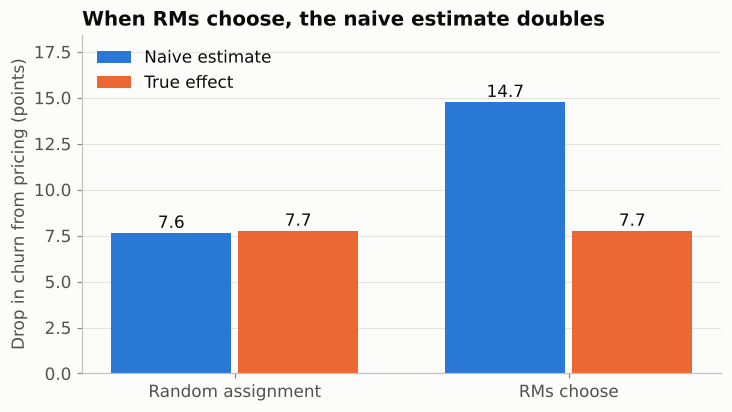

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(2)
w = 0.36
b1 = ax.bar(x - w / 2 - 0.01, compare["naive estimate (pts)"], w, color=P.BLUE, label="Naive estimate")
b2 = ax.bar(x + w / 2 + 0.01, compare["true average uplift (pts)"], w, color=P.ORANGE, label="True effect")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{b.get_height():.1f}",
                ha="center", color=P.INK, fontsize=11)
ax.set_xticks(x, compare.index)
ax.set_ylabel("Drop in churn from pricing (points)")
ax.set_ylim(0, compare.values[:, :2].max() * 1.25)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("When RMs choose, the naive estimate doubles")
P.save(fig, "08_naive_vs_truth")
plt.show()

With random assignment, simply comparing treated and control churn recovers the truth. When RMs choose, the same comparison reports **about double** the real effect. A bank acting on that number would expect twice the retention it will actually get.

## 3. Why: the groups are no longer alike

Randomisation guarantees that treated and control clients are similar **on average**, in every respect, measured or not. Choice by people does not. Compare the two groups on a few characteristics using the **standardised mean difference** (treated mean minus control mean, divided by the pooled standard deviation). Values beyond ±0.1 are conventionally called imbalanced.

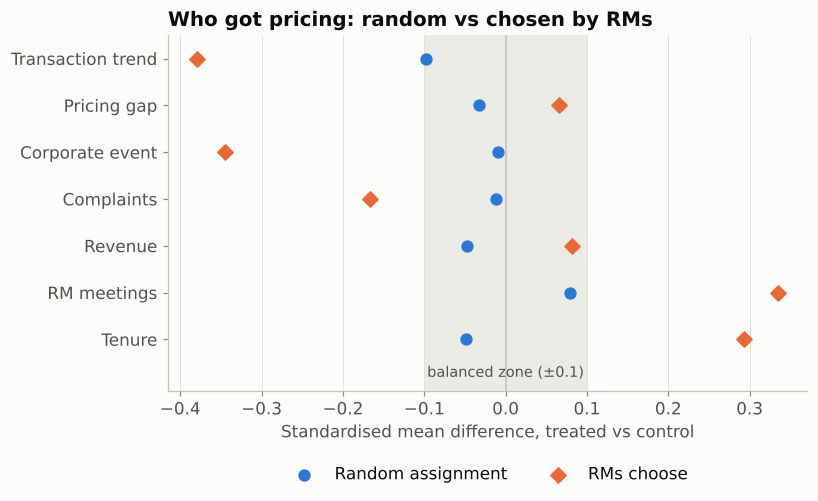

,Random assignment,RMs choose
true churn risk with no action (%),,
treated,24.500,17.400
control,23.800,25.500


In [5]:
cols = ["tenure_years", "rm_meetings_6m", "revenue_ttm", "complaints_6m", "corporate_event",
        "pricing_gap", "txn_volume_trend"]
labels = {"tenure_years": "Tenure", "rm_meetings_6m": "RM meetings", "revenue_ttm": "Revenue",
          "complaints_6m": "Complaints", "corporate_event": "Corporate event",
          "pricing_gap": "Pricing gap", "txn_volume_trend": "Transaction trend"}
smd = pd.DataFrame({
    "Random assignment": standardized_mean_differences(random_pool, cols),
    "RMs choose": standardized_mean_differences(rm_pool, cols),
})
smd.index = [labels[c] for c in smd.index]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
y = np.arange(len(smd))
ax.axvspan(-0.1, 0.1, color=P.GRID, alpha=0.6, linewidth=0)
ax.axvline(0, color=P.BASELINE, linewidth=1)
ax.scatter(smd["Random assignment"], y, color=P.BLUE, s=50, label="Random assignment", zorder=3)
ax.scatter(smd["RMs choose"], y, color=P.ORANGE, marker="D", s=50, label="RMs choose", zorder=3)
ax.set_yticks(y, smd.index)
ax.set_xlabel("Standardised mean difference, treated vs control")
ax.set_ylim(-1.1, len(smd) - 0.5)
ax.text(0, -0.8, "balanced zone (±0.1)", ha="center", color=P.INK_SECONDARY, fontsize=9.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.grid(axis="y", visible=False)
ax.set_title("Who got pricing: random vs chosen by RMs")
P.save(fig, "08_imbalance")
plt.show()

risk = pd.DataFrame({
    w: {"treated": p.loc[p["treated"] == 1, "true_p_churn_no_action"].mean(),
        "control": p.loc[p["treated"] == 0, "true_p_churn_no_action"].mean()}
    for w, p in {"Random assignment": random_pool, "RMs choose": rm_pool}.items()
})
(100 * risk).round(1).rename_axis("true churn risk with no action (%)")

Under random assignment every characteristic sits in the balanced zone. When RMs choose, the clients who got pricing have longer tenure, more RM meetings and more revenue, and far fewer complaints and corporate events. They are the **easy** clients. Because the list itself was built from churn risk, they also differ on other risk factors, such as transaction trend: an easy client only makes the list if something else looks worrying.

The last table is the heart of it: the clients RMs picked had a churn risk of about 17% **even with no call**, against about 26% for the clients they skipped. Part of the gap the naive comparison credits to pricing was there before anyone picked up the phone.

This is **confounding**: something (client easiness) influences both *who gets treated* and *the outcome*, so treatment and outcome move together even where treatment does nothing.

## 4. The causal diagram

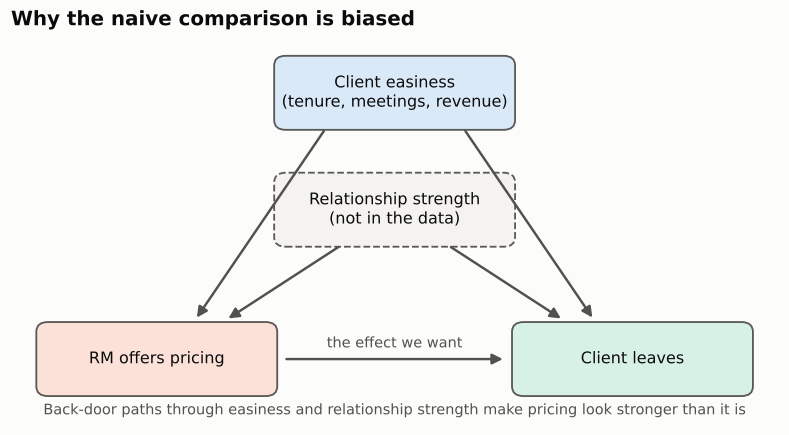

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

def node(x, y, text, color, dashed=False):
    box = FancyBboxPatch((x - 1.55, y - 0.55), 3.1, 1.1, boxstyle="round,pad=0.02,rounding_size=0.15",
                         facecolor=color, edgecolor=P.INK_SECONDARY, linewidth=1.2,
                         linestyle="--" if dashed else "-", alpha=0.95)
    ax.add_patch(box)
    ax.text(x, y, text, ha="center", va="center", fontsize=10.5, color=P.INK)

def arrow(x1, y1, x2, y2, label=None, lx=0, ly=0):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=P.INK_SECONDARY, linewidth=1.6, mutation_scale=14))
    if label:
        ax.text((x1 + x2) / 2 + lx, (y1 + y2) / 2 + ly, label, ha="center", fontsize=9.5,
                color=P.INK_SECONDARY)

node(5, 5.1, "Client easiness\n(tenure, meetings, revenue)", "#d9e8f8")
node(5, 3.3, "Relationship strength\n(not in the data)", "#f4f3ef", dashed=True)
node(1.9, 1.0, "RM offers pricing", "#fbe0d6")
node(8.1, 1.0, "Client leaves", "#d6f1e6")

arrow(3.55, 1.0, 6.45, 1.0, "the effect we want", ly=0.18)
arrow(4.1, 4.55, 2.4, 1.6)
arrow(5.9, 4.55, 7.6, 1.6)
arrow(4.3, 2.75, 2.8, 1.6)
arrow(5.7, 2.75, 7.2, 1.6)
ax.text(5, 0.15, "Back-door paths through easiness and relationship strength make pricing look stronger than it is",
        ha="center", fontsize=9.5, color=P.INK_SECONDARY)
ax.set_title("Why the naive comparison is biased", loc="left")
P.save(fig, "08_causal_diagram")
plt.show()

Read the diagram as: arrows are causes. The arrow we care about runs from **RM offers pricing** to **client leaves**. But two other routes connect them, both through characteristics that make an RM choose a client *and* make that client stay. These are called **back-door paths**. A naive comparison measures all routes at once.

Causal inference methods try to **block the back doors**: compare clients only with others who share the same easiness. That works for anything recorded in the data (tenure, meetings, revenue). It cannot work for what is not recorded, like the strength of a personal relationship, drawn dashed. Part 9 blocks the measured paths; Part 10 deals with the hidden one.

## 5. What the bias does to an uplift model

Train the same T-learner as in Part 4, once on the RM-chosen history and once on the randomised history, and check both against the truth on the same test clients.

In [7]:
rm_train, rm_test = split_pool(rm_pool, test_size=0.3, seed=0)
rand_train, _ = split_pool(random_pool, test_size=0.3, seed=0)

rm_test["from_rm_history"] = TLearner().fit(rm_train).predict_uplift(rm_test)
rm_test["from_random_history"] = TLearner().fit(rand_train).predict_uplift(rm_test)

K = 300
best = rm_test.nlargest(K, "true_uplift")["true_uplift"].sum()
pd.DataFrame({
    name: {
        "average predicted uplift (pts)": 100 * rm_test[col].mean(),
        "average true uplift (pts)": 100 * rm_test["true_uplift"].mean(),
        "correlation with true uplift": np.corrcoef(rm_test[col], rm_test["true_uplift"])[0, 1],
        "clients saved by top 300": rm_test.nlargest(K, col)["true_uplift"].sum(),
        "share of best possible": rm_test.nlargest(K, col)["true_uplift"].sum() / best,
    }
    for name, col in {"Trained on RM-chosen history": "from_rm_history",
                      "Trained on randomised history": "from_random_history"}.items()
})

,Trained on RM-chosen history,Trained on randomised history
average predicted uplift (pts),14.559,9.238
average true uplift (pts),8.111,8.111
correlation with true uplift,0.230,0.530
clients saved by top 300,29.254,46.916
share of best possible,0.437,0.701


The model trained on RM-chosen history **overstates** the average effect and **ranks clients worse**: its correlation with the truth drops sharply and its top 300 save far fewer clients. It has partly learned *"the kind of client RMs like to call tends to stay"*, which is not the effect of pricing.

### And the validation is fooled too

Part 5's uplift-by-bin table compares treated and control clients inside each bin. On RM-chosen data, the treated clients in every bin are the easy ones, so the "actual" uplift is biased as well.

In [8]:
bins = uplift_by_bin(rm_test, "from_rm_history", 5)
bins["true_uplift"] = rm_test.groupby(assign_bins(rm_test, "from_rm_history", 5))["true_uplift"].mean()
(100 * bins[["predicted_uplift", "actual_uplift", "true_uplift"]]).round(1).rename_axis("bin")

,predicted_uplift,actual_uplift,true_uplift
bin,,,
1,38.100,14.700,9.800
2,19.600,15.600,14.200
3,13.000,7.500,9.900
4,6.800,8.000,6.400
5,-4.600,5.700,0.300


The measured "actual" uplift sits above the truth in four of the five bins, and it is far too flat to reveal how poorly the model ranks. On observational data, the standard checks can wave a biased model through. Part 9 shows how to reweight them.

## 6. Why banking data is observational

In institutional banking, the clean experiment of Act 2 is rare:

- **RMs own the relationship.** They decide whom to call, and their judgement uses information no dataset fully captures.
- **Pricing is negotiated**, not assigned. The final concession depends on the conversation, the client's leverage and the RM's authority.
- **Experiments feel risky.** Deliberately *not* contacting an at-risk client worth millions is a hard sell, and pricing decisions can carry fairness and conduct expectations that make teams cautious about randomising them.
- **History is all you have.** Most uplift projects start from years of RM-chosen interventions.

So the realistic starting point is observational data, and the realistic job is to correct for how it was generated.

## Takeaways

- Every client has two **potential outcomes**; we see one. Uplift is a **CATE**: an average effect for clients like this one.
- **Random assignment** makes the naive comparison unbiased. **RM choice** does not: here it doubled the estimate.
- The cause is **confounding**: client easiness drives both the RM's choice and churn, opening **back-door paths**.
- Bias damages the uplift model's **ranking**, its **size**, and even its **validation**.
- In banking, observational data is the norm, so correcting for it is part of the job.

**Next, Part 9:** blocking the measured back doors with propensity scores, first by simple counting, then with weights.